In [ ]:
import os
import sys

# Add the project root to Python's path
project_root = os.path.abspath("..")
sys.path.append(project_root)

print(project_root)

c:\vscode\Toxicity project


In [2]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\vscode\Toxicity project\.venv\Scripts\python.exe
Python version: 3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]


In [3]:
%pip install --upgrade pip
%pip install matplotlib seaborn

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------- ----- 1.6/1.8 MB 9.4 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 8.7 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.2.1
    Uninstalling pip-26.2.1:
      Successfully uninstalled pip-26.2.1
Note: you may need to restart the kernel to use updated packages.
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------- ----------------------------- 2.4/9.3 MB 13.0 MB/s eta 0:00:01
   ----------------- ---------------------- 4.2/9.3 MB 12.8 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.3 MB 9.9 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 8.3 MB/s eta 0:00:01


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside notebook
%matplotlib inline
df = pd.read_csv("../data/train.csv")
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [3]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])
df.columns
df.info()
df.isnull().sum()
df.describe()
print("Duplicate Rows:", df.duplicated().sum())


Rows : 159571
Columns : 8
<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 72.2 MB
Duplicate Rows: 0


In [4]:
# Sum of each toxicity label
df.iloc[:, 2:].sum()

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64

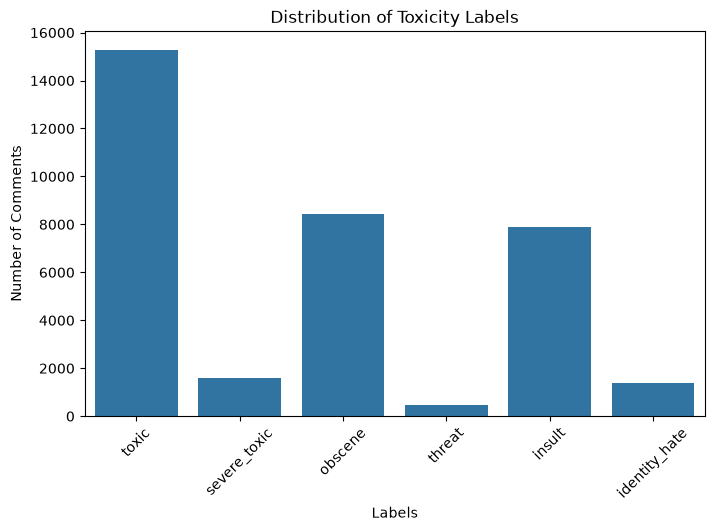

In [5]:
label_counts = df.iloc[:,2:].sum()

plt.figure(figsize=(8,5))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.title("Distribution of Toxicity Labels")
plt.xlabel("Labels")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)

plt.show()

In [6]:
df["comment_length"] = df["comment_text"].apply(len)

df["comment_length"].describe()

count    159571.000000
mean        394.073221
std         590.720282
min           6.000000
25%          96.000000
50%         205.000000
75%         435.000000
max        5000.000000
Name: comment_length, dtype: float64

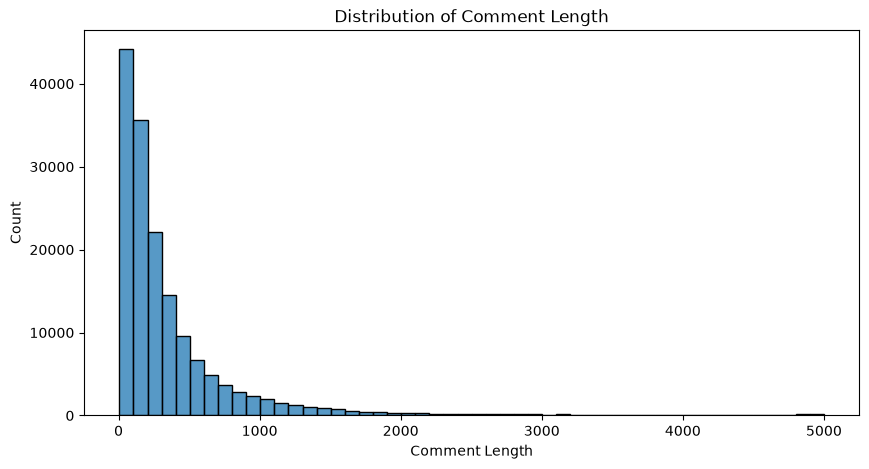

In [7]:
plt.figure(figsize=(10,5))

sns.histplot(df["comment_length"], bins=50)

plt.title("Distribution of Comment Length")
plt.xlabel("Comment Length")
plt.ylabel("Count")

plt.show()

In [8]:
df.loc[df["comment_length"].idxmax(), "comment_text"]

'ii CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARRES

In [9]:
df.loc[df["comment_length"].idxmin(), "comment_text"]

'14:53,'

In [10]:
toxic_percentage = (df["toxic"].sum() / len(df)) * 100

print(f"Toxic Comments: {toxic_percentage:.2f}%")

Toxic Comments: 9.58%


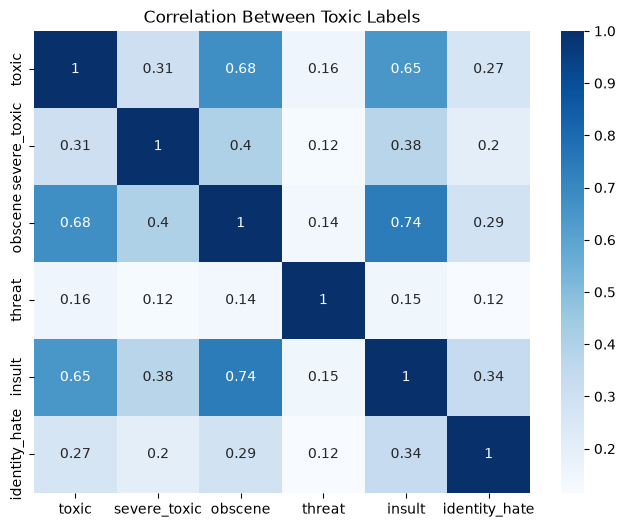

In [11]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.iloc[:,2:8].corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Between Toxic Labels")

plt.show()

In [14]:
df[df["toxic"] == 1][["comment_text"]].head(10)

,comment_text
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK
12,Hey... what is it..\n@ | talk .\nWhat is it......
16,"Bye! \n\nDon't look, come or think of comming ..."
42,You are gay or antisemmitian? \n\nArchangel WH...
43,"FUCK YOUR FILTHY MOTHER IN THE ASS, DRY!"
44,I'm Sorry \n\nI'm sorry I screwed around with ...
51,GET FUCKED UP. GET FUCKEEED UP. GOT A DRINK T...
55,Stupid peace of shit stop deleting my stuff as...
56,=Tony Sidaway is obviously a fistfuckee. He lo...
58,My Band Page's deletion. You thought I was gon...


In [12]:
df[df["toxic"] == 0][["comment_text"]].head(10)

,comment_text
0,Explanation\nWhy the edits made under my usern...
1,D'aww! He matches this background colour I'm s...
2,"Hey man, I'm really not trying to edit war. It..."
3,"""\nMore\nI can't make any real suggestions on ..."
4,"You, sir, are my hero. Any chance you remember..."
5,"""\n\nCongratulations from me as well, use the ..."
7,Your vandalism to the Matt Shirvington article...
8,Sorry if the word 'nonsense' was offensive to ...
9,alignment on this subject and which are contra...
10,"""\nFair use rationale for Image:Wonju.jpg\n\nT..."


In [13]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [14]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [15]:
tokenizer = Tokenizer(num_words=20000)
tokenizer.fit_on_texts(df["comment_text"])

In [16]:
sequences = tokenizer.texts_to_sequences(df["comment_text"])

In [25]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_length = 200

X = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [18]:
# Create one mutually exclusive target class for every comment
class_names = [
    "non-toxic",
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

# Apply a priority rule where a comment has multiple positive labels
conditions = [
    df["severe_toxic"] == 1,
    df["threat"] == 1,
    df["identity_hate"] == 1,
    df["obscene"] == 1,
    df["insult"] == 1,
    df["toxic"] == 1
]

choices = [
    "severe_toxic",
    "threat",
    "identity_hate",
    "obscene",
    "insult",
    "toxic"
]

df["class_label"] = np.select(conditions, choices, default="non-toxic")

# Convert class labels into integer IDs for model training
class_to_id = {name: index for index, name in enumerate(class_names)}
id_to_class = {index: name for name, index in class_to_id.items()}
df["class_id"] = df["class_label"].map(class_to_id)

print("Class distribution:")
print(df["class_label"].value_counts().reindex(class_names, fill_value=0))

Class distribution:
class_label
non-toxic        143346
toxic              5666
severe_toxic       1595
obscene            6056
threat              366
insult             1516
identity_hate      1026
Name: count, dtype: int64


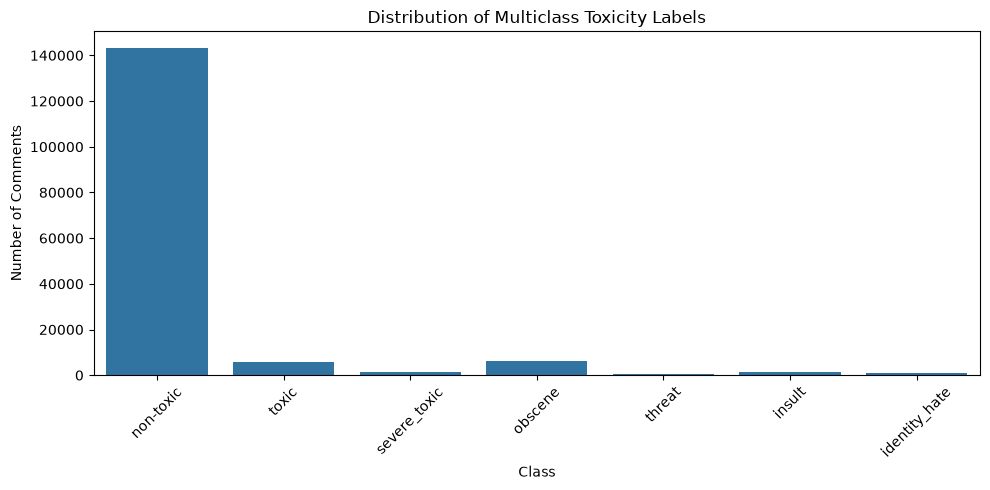

In [19]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="class_label", order=class_names)
plt.title("Distribution of Multiclass Toxicity Labels")
plt.xlabel("Class")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [23]:
X = X_padded

y = df["class_id"].to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)

NameError: name 'X_padded' is not defined

In [ ]:
from sklearn.model_selection import train_test_split
# Define the target variable
y = df["class_id"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

NameError: name 'y' is not defined

In [12]:
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (127656, 200)
Testing : (31915, 200)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential()

# Embedding Layer
model.add(Embedding(input_dim=20000, output_dim=128, input_length=200))

# LSTM Layer
model.add(LSTM(64))

# Dropout Layer
model.add(Dropout(0.5))

# Seven output neurons: one for each mutually exclusive class
model.add(Dense(len(class_names), activation="softmax"))

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_ids = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_train
)
class_weights = {int(class_id): float(weight) for class_id, weight in zip(class_ids, weights)}

history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.2,
    class_weight=class_weights
)


In [17]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

998/998 ━━━━━━━━━━━━━━━━━━━━ 22s 22ms/step - accuracy: 0.9608 - loss: 0.1114
Test Loss: 0.11139427870512009
Test Accuracy: 0.9608021378517151


In [ ]:
# Predict the probability for each of the seven classes
y_pred_prob = model.predict(X_test)

# Select the class with the highest predicted probability
y_pred = np.argmax(y_pred_prob, axis=1)


998/998 ━━━━━━━━━━━━━━━━━━━━ 25s 24ms/step


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print(classification_report(
    y_test,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


              precision    recall  f1-score   support

           0       0.97      0.98      0.98     28859
           1       0.83      0.74      0.78      3056

    accuracy                           0.96     31915
   macro avg       0.90      0.86      0.88     31915
weighted avg       0.96      0.96      0.96     31915



In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(len(class_names))))

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - Multiclass Toxicity Classification")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
import os
import json

os.makedirs("../models", exist_ok=True)

model.save("../models/toxicity_multiclass_model.keras")

with open("../models/class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)


In [21]:
import pickle

with open("../models/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

In [ ]:
sample = ["You are a wonderful person"]

seq = tokenizer.texts_to_sequences(sample)
padded = pad_sequences(seq, maxlen=max_length, padding="post", truncating="post")

prediction_probabilities = model.predict(padded)
predicted_class_id = int(np.argmax(prediction_probabilities, axis=1)[0])
predicted_class = id_to_class[predicted_class_id]

print("Predicted class:", predicted_class)
print("Class probabilities:")
for class_name, probability in zip(class_names, prediction_probabilities[0]):
    print(f"{class_name}: {probability:.4f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
[[0.4315223]]


In [ ]:
sample = ["I hate you. You are an idiot."]

seq = tokenizer.texts_to_sequences(sample)
padded = pad_sequences(seq, maxlen=max_length, padding="post", truncating="post")

prediction_probabilities = model.predict(padded)
predicted_class_id = int(np.argmax(prediction_probabilities, axis=1)[0])
predicted_class = id_to_class[predicted_class_id]

print("Predicted class:", predicted_class)
print("Class probabilities:")
for class_name, probability in zip(class_names, prediction_probabilities[0]):
    print(f"{class_name}: {probability:.4f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
[[0.50771487 0.4966765  0.5009756  0.4994789  0.4939541  0.4997161 ]]


In [28]:
import sys
print(sys.executable)

c:\Users\rpsar\AppData\Local\Programs\Python\Python313\python.exe
